In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [3]:
# 1. Load Dataset
data = pd.read_csv('dataset_timnas.csv')
print("Total baris awal:", len(data))
print("Kolom:", data.columns.tolist())

Total baris awal: 545
Kolom: ['text', 'created_at', 'like_count', 'repost_count', 'reply_count', 'url', 'kata_kunci', 'lang', 'text_clean']


In [4]:
x_col = 'like_count'    # Variabel Bebas (X)
y_col = 'repost_count'  # Variabel Terikat (Y)

print("\nVariabel Bebas (X):", x_col)
print("Variabel Terikat (Y):", y_col)


Variabel Bebas (X): like_count
Variabel Terikat (Y): repost_count


In [5]:
# 3. Pembersihan Data (Missing Value & Validasi Tipe Data)
print(f"Jumlah {x_col} kosong:", data[x_col].isna().sum())
print(f"Jumlah {y_col} kosong:", data[y_col].isna().sum())

data = data.dropna(subset=[x_col, y_col])
data[x_col] = pd.to_numeric(data[x_col], errors='coerce')
data[y_col] = pd.to_numeric(data[y_col], errors='coerce')
data = data.dropna(subset=[x_col, y_col])
data = data.reset_index(drop=True)

print("Total baris setelah filter:", len(data))

Jumlah like_count kosong: 0
Jumlah repost_count kosong: 0
Total baris setelah filter: 545


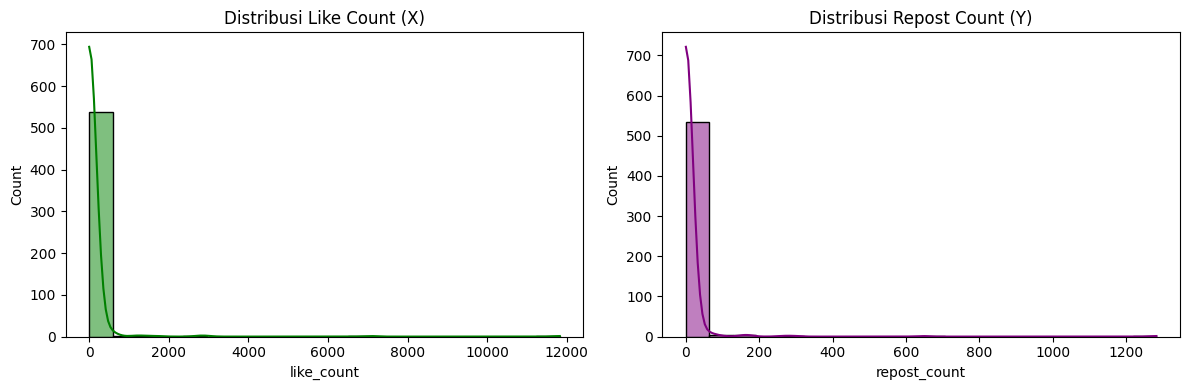

In [6]:
# 4. EDA (Exploratory Data Analysis)
# Distribusi Data
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data[x_col], bins=20, kde=True, ax=axes[0], color='green')
axes[0].set_title('Distribusi Like Count (X)')

sns.histplot(data[y_col], bins=20, kde=True, ax=axes[1], color='purple')
axes[1].set_title('Distribusi Repost Count (Y)')

plt.tight_layout()
plt.show()

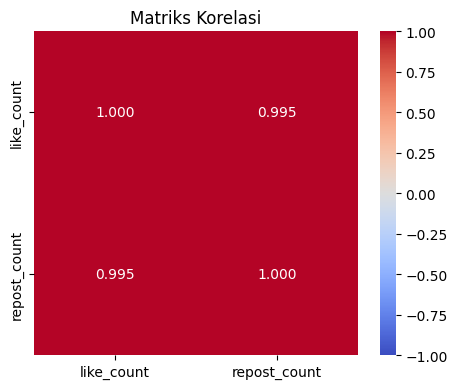

              like_count  repost_count
like_count      1.000000      0.995402
repost_count    0.995402      1.000000


In [7]:
# Matriks Korelasi
plt.figure(figsize=(5, 4))
corr = data[[x_col, y_col]].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1, square=True)
plt.title('Matriks Korelasi')
plt.tight_layout()
plt.show()
print(corr)

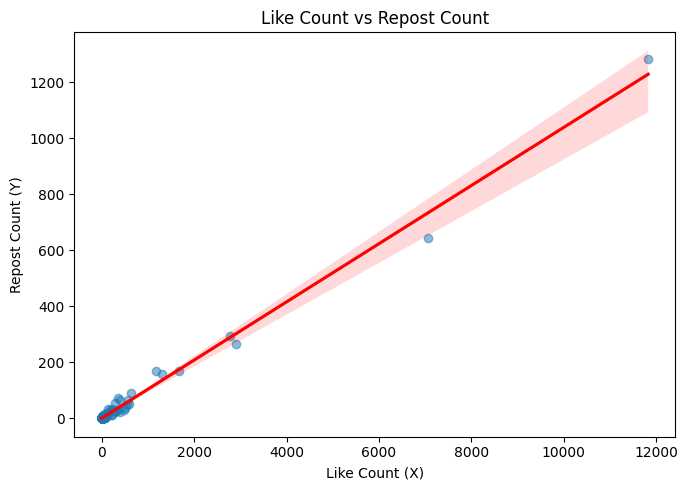

In [8]:
# Scatter Plot & Garis Regresi
plt.figure(figsize=(7, 5))
sns.regplot(data=data, x=x_col, y=y_col,
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
plt.title('Like Count vs Repost Count')
plt.xlabel('Like Count (X)')
plt.ylabel('Repost Count (Y)')
plt.tight_layout()
plt.show()

In [9]:
# 5. Persiapan Data untuk Model (Train-Test Split)
X = data[[x_col]]  # Format 2D array untuk scikit-learn
y = data[y_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data latih:", len(X_train))
print("Data uji:", len(X_test))

Data latih: 436
Data uji: 109


In [10]:
# 6. Pelatihan Model Regresi Linear
model = LinearRegression()
model.fit(X_train, y_train)

print("\nIntercept:", model.intercept_)
print("Koefisien Like Count:", model.coef_[0])


Intercept: 0.22151487451978946
Koefisien Like Count: 0.10252432472374731


MAE: 2.74
R² : 0.9932


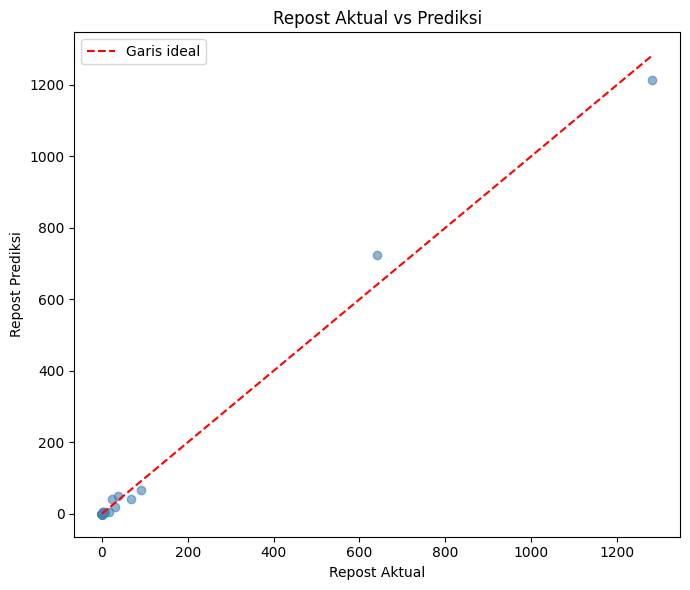

In [11]:
# 7. Evaluasi Model
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"R² : {r2:.4f}")

# Visualisasi Aktual vs Prediksi
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='steelblue')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--', label='Garis ideal')
plt.xlabel('Repost Aktual')
plt.ylabel('Repost Prediksi')
plt.title('Repost Aktual vs Prediksi')
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# 8. Contoh Prediksi Menggunakan Data Baru
contoh_likes = 150
input_data = pd.DataFrame({
    x_col: [contoh_likes]
})

pred = model.predict(input_data)[0]
print(f"\nEstimasi jumlah repost untuk {contoh_likes} likes: {pred:.2f}")

if pred < 0:
    print("⚠️ Hasil negatif → tidak bermakna sebagai jumlah repost (keterbatasan model)")


Estimasi jumlah repost untuk 150 likes: 15.60
